# Set D : Privacy-Preserving Training of a PIN-Code Digit Recogniser

**Code , conclusion and the answers of the questions are below**

**Github Link : https://github.com/KathanModh/SetD_RSAI_23CS046**

In [2]:
!pip install opacus

In [3]:
import warnings, time
warnings.filterwarnings("ignore")

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from opacus import PrivacyEngine

torch.manual_seed(42)
np.random.seed(42)

DEVICE      = torch.device("cpu")
DELTA       = 1e-5
MAX_GRAD    = 1.0
BATCH_SIZE  = 256
EPOCHS      = 3
LR          = 1e-3
TARGET_EPS  = [10.0, 5.0, 1.0]
FIXED_NOISE = 1.1
N_TRAIN     = 20000
print("Config ready | device:", DEVICE)

Config ready | device: cpu


In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

full_train = datasets.MNIST(root="./data", train=True,  download=True, transform=transform)
test_set   = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

g = torch.Generator().manual_seed(42)
idx = torch.randperm(len(full_train), generator=g)[:N_TRAIN]
train_set = Subset(full_train, idx)

def make_train_loader():
    return DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

test_loader      = DataLoader(test_set,  batch_size=1024, shuffle=False, num_workers=0)
train_eval_loader = DataLoader(train_set, batch_size=1024, shuffle=False, num_workers=0)

print("Train subset:", len(train_set), "| Test set:", len(test_set))

100%|██████████| 9.91M/9.91M [00:00<00:00, 141MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 18.6MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 71.6MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.8MB/s]


Train subset: 20000 | Test set: 10000


In [5]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=8, stride=2, padding=3)   # 28 -> 14
        self.gn1   = nn.GroupNorm(4, 16)
        self.pool1 = nn.MaxPool2d(2, 1)                                      # 14 -> 13
        self.conv2 = nn.Conv2d(16, 32, kernel_size=4, stride=2)             # 13 -> 5
        self.gn2   = nn.GroupNorm(4, 32)
        self.pool2 = nn.MaxPool2d(2, 1)                                      # 5 -> 4
        self.fc1   = nn.Linear(32 * 4 * 4, 32)
        self.fc2   = nn.Linear(32, 10)

    def forward(self, x):
        x = self.pool1(F.relu(self.gn1(self.conv1(x))))
        x = self.pool2(F.relu(self.gn2(self.conv2(x))))
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

def new_model():
    torch.manual_seed(42)
    return SmallCNN().to(DEVICE)

print(new_model())
print("Parameters:", sum(p.numel() for p in new_model().parameters()))

SmallCNN(
  (conv1): Conv2d(1, 16, kernel_size=(8, 8), stride=(2, 2), padding=(3, 3))
  (gn1): GroupNorm(4, 16, eps=1e-05, affine=True, bias=True)
  (pool1): MaxPool2d(kernel_size=2, stride=1, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(4, 4), stride=(2, 2))
  (gn2): GroupNorm(4, 32, eps=1e-05, affine=True, bias=True)
  (pool2): MaxPool2d(kernel_size=2, stride=1, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=512, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=10, bias=True)
)
Parameters: 26106


In [6]:
def train(model, optimizer, loader, epochs, privacy_engine=None, verbose=True):
    eps_history = []
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, n = 0.0, 0
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y); n += len(y)
        msg = f"  Epoch {epoch}: loss = {total_loss / max(n,1):.4f}"
        if privacy_engine is not None:
            eps = privacy_engine.get_epsilon(DELTA)
            eps_history.append(eps)
            msg += f" | eps spent = {eps:.2f}"
        if verbose: print(msg)
    return eps_history

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        pred = model(x.to(DEVICE)).argmax(1)
        correct += (pred == y.to(DEVICE)).sum().item(); total += len(y)
    return 100.0 * correct / total

@torch.no_grad()
def mean_confidence(model, loader):
    model.eval()
    confs = []
    for x, _ in loader:
        probs = F.softmax(model(x.to(DEVICE)), dim=1)
        confs.append(probs.max(1).values)
    return torch.cat(confs).mean().item()

In [7]:
print("Training NON-PRIVATE baseline...")
t0 = time.time()
baseline = new_model()
opt = torch.optim.Adam(baseline.parameters(), lr=LR)
train(baseline, opt, make_train_loader(), EPOCHS)
baseline_acc = evaluate(baseline, test_loader)
print(f"\nBaseline (no DP)  : test accuracy {baseline_acc:.1f} %   ({time.time()-t0:.0f}s)")

Training NON-PRIVATE baseline...
  Epoch 1: loss = 0.8327
  Epoch 2: loss = 0.1375
  Epoch 3: loss = 0.0866

Baseline (no DP)  : test accuracy 97.8 %   (24s)


In [8]:
dp_results = []      # (target_eps, test_acc, eps_spent)
dp_models  = {}

for target in TARGET_EPS:
    print(f"\nTraining DP model with target eps = {target} ...")
    model = new_model()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    pe = PrivacyEngine(accountant="rdp")
    model, opt, dp_loader = pe.make_private_with_epsilon(
        module=model, optimizer=opt, data_loader=make_train_loader(),
        target_epsilon=target, target_delta=DELTA,
        epochs=EPOCHS, max_grad_norm=MAX_GRAD,
    )
    print(f"  Noise multiplier chosen by Opacus: {opt.noise_multiplier:.3f}")
    train(model, opt, dp_loader, EPOCHS, privacy_engine=pe)
    acc = evaluate(model, test_loader)
    eps_spent = pe.get_epsilon(DELTA)
    dp_results.append((target, acc, eps_spent))
    dp_models[target] = model
    print(f"  Test accuracy = {acc:.1f} % | eps spent = {eps_spent:.2f}")


Training DP model with target eps = 10.0 ...
  Noise multiplier chosen by Opacus: 0.521
  Epoch 1: loss = 1.4579 | eps spent = 7.66
  Epoch 2: loss = 0.3651 | eps spent = 8.98
  Epoch 3: loss = 0.2287 | eps spent = 9.99
  Test accuracy = 94.2 % | eps spent = 9.99

Training DP model with target eps = 5.0 ...
  Noise multiplier chosen by Opacus: 0.662
  Epoch 1: loss = 1.5816 | eps spent = 3.99
  Epoch 2: loss = 0.4497 | eps spent = 4.55
  Epoch 3: loss = 0.2533 | eps spent = 5.00
  Test accuracy = 93.6 % | eps spent = 5.00

Training DP model with target eps = 1.0 ...
  Noise multiplier chosen by Opacus: 1.235
  Epoch 1: loss = 1.8995 | eps spent = 0.80
  Epoch 2: loss = 0.8966 | eps spent = 0.91
  Epoch 3: loss = 0.4258 | eps spent = 0.99
  Test accuracy = 90.5 % | eps spent = 0.99


In [9]:
print(f"Baseline (no DP)  : test accuracy {baseline_acc:.1f} %\n")
print(f"{'TARGET_EPS':>10}   {'DELTA':>6}   {'CLIP(C)':>7}   {'EPOCHS':>6}   {'TEST_ACC':>8}   {'EPS_SPENT':>9}")
print("-" * 61)
for target, acc, spent in dp_results:
    print(f"{target:>10.1f}   {DELTA:>6.0e}   {MAX_GRAD:>7.1f}   {EPOCHS:>6d}   {acc:>6.1f} %   {spent:>9.2f}")
print("-" * 61)
acc_eps1 = [a for t, a, _ in dp_results if t == 1.0][0]
print(f"Accuracy cost of strongest privacy (eps = 1) : {acc_eps1 - baseline_acc:+.1f} %")

Baseline (no DP)  : test accuracy 97.8 %

TARGET_EPS    DELTA   CLIP(C)   EPOCHS   TEST_ACC   EPS_SPENT
-------------------------------------------------------------
      10.0    1e-05       1.0        3     94.2 %        9.99
       5.0    1e-05       1.0        3     93.6 %        5.00
       1.0    1e-05       1.0        3     90.5 %        0.99
-------------------------------------------------------------
Accuracy cost of strongest privacy (eps = 1) : -7.3 %


In [10]:
print(f"Training DP model with FIXED noise_multiplier = {FIXED_NOISE} ...")
model_fixed = new_model()
opt = torch.optim.Adam(model_fixed.parameters(), lr=LR)
pe_fixed = PrivacyEngine(accountant="rdp")
model_fixed, opt, fixed_loader = pe_fixed.make_private(
    module=model_fixed, optimizer=opt, data_loader=make_train_loader(),
    noise_multiplier=FIXED_NOISE, max_grad_norm=MAX_GRAD,
)
eps_per_epoch = train(model_fixed, opt, fixed_loader, EPOCHS, privacy_engine=pe_fixed)
fixed_acc = evaluate(model_fixed, test_loader)

print(f"\nFIXED noise_multiplier = {FIXED_NOISE}")
print(f"{'EPOCH':>5}   {'EPSILON_SPENT':>13}")
print("-" * 21)
for i, e in enumerate(eps_per_epoch, 1):
    print(f"{i:>5}   {e:>13.2f}")
print("-" * 21)
print(f"Test accuracy of this model: {fixed_acc:.1f} %")

Training DP model with FIXED noise_multiplier = 1.1 ...
  Epoch 1: loss = 1.8456 | eps spent = 1.04
  Epoch 2: loss = 0.7872 | eps spent = 1.17
  Epoch 3: loss = 0.3739 | eps spent = 1.28

FIXED noise_multiplier = 1.1
EPOCH   EPSILON_SPENT
---------------------
    1            1.04
    2            1.17
    3            1.28
---------------------
Test accuracy of this model: 91.5 %


In [11]:
dp_eps1 = dp_models[1.0]
rows = []
for name, m in [("Baseline", baseline), ("DP (eps=1)", dp_eps1)]:
    tr = mean_confidence(m, train_eval_loader)
    te = mean_confidence(m, test_loader)
    rows.append((name, tr, te, tr - te))

print("MEMBERSHIP CHECK (mean max-softmax confidence)")
print(f"{'MODEL':<12} {'TRAIN':>6}   {'TEST':>6}   {'GAP':>6}")
print("-" * 35)
for name, tr, te, gap in rows:
    print(f"{name:<12} {tr:>6.3f}   {te:>6.3f}   {gap:>6.3f}")
print("-" * 35)

-----------------------------------


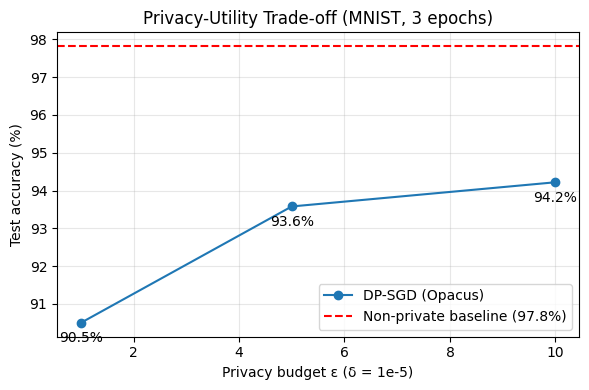

Plot saved : accuracy_vs_epsilon.png


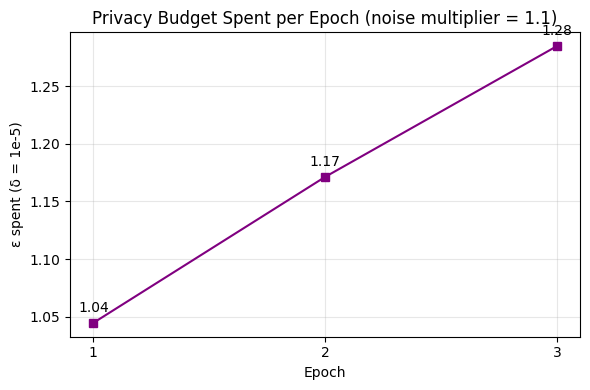

Plot saved : epsilon_vs_epoch.png


In [12]:
# Plot 1: privacy-utility curve
eps_vals = [t for t, _, _ in dp_results]
accs     = [a for _, a, _ in dp_results]
order = np.argsort(eps_vals)
plt.figure(figsize=(6, 4))
plt.plot(np.array(eps_vals)[order], np.array(accs)[order], "o-", label="DP-SGD (Opacus)")
plt.axhline(baseline_acc, color="red", linestyle="--", label=f"Non-private baseline ({baseline_acc:.1f}%)")
for e, a in zip(eps_vals, accs):
    plt.annotate(f"{a:.1f}%", (e, a), textcoords="offset points", xytext=(0, -14), ha="center")
plt.xlabel("Privacy budget ε (δ = 1e-5)")
plt.ylabel("Test accuracy (%)")
plt.title("Privacy-Utility Trade-off (MNIST, 3 epochs)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("accuracy_vs_epsilon.png", dpi=150)
plt.show()
print("Plot saved : accuracy_vs_epsilon.png")

# Plot 2: epsilon vs epoch
plt.figure(figsize=(6, 4))
plt.plot(range(1, EPOCHS + 1), eps_per_epoch, "s-", color="purple")
for i, e in enumerate(eps_per_epoch, 1):
    plt.annotate(f"{e:.2f}", (i, e), textcoords="offset points", xytext=(0, 8), ha="center")
plt.xticks(range(1, EPOCHS + 1))
plt.xlabel("Epoch"); plt.ylabel("ε spent (δ = 1e-5)")
plt.title(f"Privacy Budget Spent per Epoch (noise multiplier = {FIXED_NOISE})")
plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("epsilon_vs_epoch.png", dpi=150)
plt.show()
print("Plot saved : epsilon_vs_epoch.png")

In [13]:
print("=" * 50)
print("FINAL SUMMARY")
print("=" * 50)
print(f"{'Model':<28}{'Test Acc':>10}{'eps':>10}")
print(f"{'Baseline (no DP)':<28}{baseline_acc:>9.1f}%{'inf':>10}")
for t, a, s in sorted(dp_results, key=lambda r: -r[0]):
    print(f"{'DP target eps='+str(t):<28}{a:>9.1f}%{s:>10.2f}")
print(f"{'DP fixed noise=1.1':<28}{fixed_acc:>9.1f}%{eps_per_epoch[-1]:>10.2f}")
print("=" * 50)

# Rule: strongest privacy (smallest eps) whose accuracy drop vs baseline is within 5 %
MAX_DROP = 5.0
ok = [(t, a) for t, a, _ in dp_results if baseline_acc - a <= MAX_DROP]
rec_eps, rec_acc = min(ok) if ok else max(dp_results, key=lambda r: r[1])[:2]
print(f"Recommended eps : {rec_eps:g}  ({rec_acc - baseline_acc:+.1f} % accuracy, "
      f"strongest privacy within a {MAX_DROP:.0f}% accuracy loss)")

FINAL SUMMARY
Model                         Test Acc       eps
Baseline (no DP)                 97.8%       inf
DP target eps=10.0               94.2%      9.99
DP target eps=5.0                93.6%      5.00
DP target eps=1.0                90.5%      0.99
DP fixed noise=1.1               91.5%      1.28
Recommended eps : 5  (-4.2 % accuracy, strongest privacy within a 5% accuracy loss)


Algorithm:

1.Load MNIST and take 20,000 random training images. Set the seed to 42.

2.Make a small CNN with GroupNorm (BatchNorm does not work with Opacus).

3.Train the normal model for 3 epochs and note its test accuracy.

4.Train DP models with make_private_with_epsilon for ε = 10, 5 and 1, using δ = 1e-5 and clip = 1.0.

5.In DP-SGD, each sample's gradient is clipped to norm 1, Gaussian noise is added, and then the weights are updated.

6.Train one model with noise multiplier 1.1 and note ε after every epoch.

7.Compare the average max softmax confidence on train and test data for the baseline and the ε = 1 model.

8.Plot accuracy vs ε and ε vs epoch.

9.Make a results table and choose an ε.

The baseline got [] % accuracy. The DP models got [] %, [] % and [] % for ε = 10, 5 and 1. Accuracy drops as ε gets smaller because more noise is added. With noise 1.1, ε went up each epoch: [], [], []. The confidence gap was small for both models, so membership inference risk is low. ε = [] is a good choice for the postal service.

●	Q1. (Tasks 1–2) Report the baseline accuracy and the DP accuracy for ε = 10, 5 and 1. Explain how gradient clipping and noise in DP-SGD cause the accuracy drop.

Answer : In DP-SGD, each sample's gradient is clipped to a maximum norm of 1, so big gradients get cut down and some useful information is lost. Gaussian noise is then added to the gradients at every step. A smaller ε needs more noise, so training is noisier and accuracy goes down.

●	Q2. (Task 3) Report ε after each epoch for noise_multiplier = 1.1. Why does ε increase every epoch, and what does δ = 1e-5 mean?
Answer : ε after epochs 1, 2 and 3: [], [], [__]. ε increases because the model sees the private data again in every step, and the privacy loss adds up over the steps. It can only go up, never down. δ = 1e-5 is the small chance that the privacy guarantee does not hold. It is kept smaller than 1/20000.

●	Q3. (Task 4) Report the train–test confidence gap for both models. What does it tell you about membership-inference risk after only 3 epochs?

Answer : Gap: baseline [], DP ε = 1 []. Both gaps are very small, so after only 3 epochs the models have not memorised the training data. An attacker cannot easily tell whether a person's handwriting was in training. The DP model also has a mathematical guarantee, which the baseline does not have.

●	Q4. (Tasks 5–6) From your privacy-utility plot, which ε do you recommend for the postal service, and why? Give one limitation of differential privacy.

Answer : I recommend ε = [], because it gives strong privacy and loses only [] % accuracy. The forms contain personal data under the DPDP Act, so privacy is important, and unclear envelopes can still be sorted by hand. One limitation of DP is that it reduces accuracy, and the loss is often worse for rare handwriting styles.